# Assistente de Investimentos com AI Agent: VALE3, PETR4, BBAS3, ITUB4

> **Aviso:** projeto experimental e educacional. As recomendações **não constituem aconselhamento financeiro** e **não garantem resultados**. Resultados históricos não indicam desempenho futuro.

**Como o agente decide:** coleta preços (`yfinance`) e notícias (`feedparser`), calcula indicadores técnicos, pontua o sentimento por léxico e aplica regras auditáveis. O registro guarda apenas evidências, regras acionadas e limitações (sem raciocínio interno do modelo). Nenhuma chave paga é necessária para o fluxo principal.

**Ordem de execução:** rode as células de cima para baixo (Kernel → *Restart & Run All*).

## 1. Preparação do ambiente

### 1.1. Configuração das chaves de API

O fluxo principal **não usa chaves**. As variáveis abaixo são opcionais e usadas apenas no modo LLM (seção 5.1):

- `OPENAI_API_KEY`: para o modelo OpenAI
- `GOOGLE_API_KEY`: para o Google Gemini

Defina-as no terminal **antes** de iniciar o Jupyter/VS Code (o kernel herda o ambiente do processo que o iniciou). Nunca escreva chaves no notebook.

In [1]:
import os

# Apenas verifica a presença das chaves; o valor nunca é lido para exibição nem gravado.
for key in ("OPENAI_API_KEY", "GOOGLE_API_KEY"):
    print(f"{key}: {'definida' if os.environ.get(key) else 'não definida (opcional)'}")

OPENAI_API_KEY: não definida (opcional)
GOOGLE_API_KEY: não definida (opcional)


### 1.2. Instalação das dependências

In [ ]:
# Execute no terminal, na raiz do projeto, usando a venv existente:
#   .venv\Scripts\python -m pip install -r requirements.txt
#   .venv\Scripts\python -m pip install -r requirements_llm.txt # opcional (seção 5.1)
import importlib.util

for mod in ("yfinance", "feedparser", "pandas", "numpy", "matplotlib"):
    print(f"{mod}: {'ok' if importlib.util.find_spec(mod) else 'FALTANDO - instale requirements.txt'}")

yfinance: ok
feedparser: ok
pandas: ok
numpy: ok
matplotlib: ok


### 1.3. Código do agente (pacote `assistant/`)

O código fica no pacote `assistant/`, ao lado deste notebook:

| Módulo | Papel |
| --- | --- |
| `config.py` | ações, feeds RSS, parâmetros e limiares |
| `data.py` | `get_price_data` (yfinance) |
| `indicators.py` | `calculate_indicators` (RSI, MACD, SMA/EMA, Bollinger, volume) |
| `sentiment.py` / `news.py` | léxico de sentimento e `search_news` (feedparser) |
| `recommendation.py` | `generate_recommendation` (regras pontuadas) |
| `agent.py` | registro de ferramentas e `InvestmentAgent` |
| `chat.py` | perguntas e respostas sobre os registros |
| `evaluation.py` / `plots.py` | avaliação walk-forward, backtest e gráficos |
| `llm_agent.py` | modo LangChain opcional (OpenAI/Gemini) |

In [ ]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from assistant import config
from assistant.agent import TOOLS, InvestmentAgent
from assistant.chat import answer
from assistant.data import get_price_data
from assistant.evaluation import evaluate_ticker
from assistant.indicators import calculate_indicators
from assistant.news import search_news
from assistant.plots import plot_backtest, plot_indicators

warnings.filterwarnings("ignore", category=FutureWarning)
%matplotlib inline
pd.set_option("display.width", 160)
print(config.DISCLAIMER)

AVISO: recomendações experimentais e educacionais. Não constituem aconselhamento financeiro e não garantem resultados. Desempenho passado não indica desempenho futuro.


## 2. Ferramentas do agente

| Ferramenta | Função |
| --- | --- |
| `search_news(ticker)` | notícias por RSS relacionadas à ação, com sentimento |
| `get_price_data(ticker, period)` | OHLCV diário ajustado via `yfinance` (ticker `.SA`) |
| `calculate_indicators(data)` | RSI, MACD, SMA/EMA, Bollinger e volume |
| `generate_recommendation(analysis)` | COMPRAR/VENDER/AGUARDAR com evidências |

Toda ferramenta de coleta retorna um `ToolResult(ok, data, error, meta)`: falhas de rede ou dados vazios viram `ok=False` com a mensagem, sem interromper o fluxo e sem dados inventados.

In [4]:
for t in TOOLS.values():
    print(f"- {t.description}")

- search_news(ticker): notícias RSS relacionadas à ação, com sentimento por notícia e score agregado.
- get_price_data(ticker, period): OHLCV diário ajustado via yfinance (ticker B3, ex.: PETR4; period ex.: '1y', '2y').
- calculate_indicators(data): RSI, MACD/sinal, SMA/EMA, Bandas de Bollinger e volume.
- generate_recommendation(analysis): COMPRAR/VENDER/AGUARDAR com sinais, justificativa e limitações.


### 2.1. Preços e indicadores (exemplo: PETR4)

In [5]:
prices = get_price_data("PETR4", config.DEFAULT_PERIOD)
if prices.ok:
    print(prices.meta)
    ind = calculate_indicators(prices.data)
    display(ind[["Close", "Volume", "RSI", "MACD", "MACD_signal", "SMA_short", "SMA_long", "EMA_fast",
                 "EMA_slow", "BB_upper", "BB_lower", "Volume_ratio"]].tail().round(3))
else:
    print("Preços indisponíveis:", prices.error)

{'ticker': 'PETR4', 'symbol': 'PETR4.SA', 'period': '2y', 'rows': 498, 'start': '2024-10-16', 'end': '2026-10-16', 'source': 'Yahoo Finance (yfinance)', 'cached': False}


,Close,Volume,RSI,MACD,MACD_signal,SMA_short,SMA_long,EMA_fast,EMA_slow,BB_upper,BB_lower,Volume_ratio
Date,,,,,,,,,,,,
2026-10-09,56.00,49809400,75.043,2.448,1.968,50.569,46.226,52.537,50.090,55.950,45.189,1.066
2026-10-13,56.85,38257100,76.683,2.610,2.097,50.966,46.521,53.201,50.590,56.938,44.994,0.813
2026-10-14,58.11,42367600,78.897,2.809,2.239,51.350,46.848,53.956,51.147,58.075,44.625,0.905
2026-10-15,57.36,37576500,74.371,2.872,2.366,51.785,47.171,54.480,51.608,58.873,44.698,0.815
2026-10-16,59.68,56657800,78.483,3.074,2.507,52.339,47.552,55.280,52.206,60.049,44.629,1.198


### 2.2. Notícias e sentimento (exemplo: PETR4)

O sentimento usa um **léxico financeiro em português** (`assistant/sentiment.py`): gratuito, offline e auditável (cada notícia mostra os termos que pontuaram). Limitações: não entende ironia, contexto nem quem é afetado; a negação tratada é só a imediatamente anterior. Só títulos e resumos dos feeds são usados; sem notícias relacionadas, o score fica indefinido (`None`) e não entra na decisão.

- **Score de sentimento** da ação: média dos scores (−1 a +1) ponderada por recência (meia-vida de 3 dias).
- **Impacto** (0 a 1): |sentimento| × cobertura (nº de notícias, saturando em 10).

In [6]:
news = search_news("PETR4")
print("Fontes OK:", news.data["sources_ok"])
print("Fontes com falha:", news.data["sources_failed"] or "nenhuma")
print("Impacto:", news.data["impact"])
print(news.data["summary"])
if news.data["items"]:
    display(pd.DataFrame(news.data["items"])[["published", "source", "title", "label", "score", "terms"]])

Fontes OK: ['InfoMoney', 'InfoMoney Mercados', 'Money Times', 'Google News (PETR4)']
Fontes com falha: nenhuma
Impacto: 0.147
15 notícia(s): 4 positiva(s), 1 negativa(s), 10 neutra(s). Sentimento agregado +0.15 (neutro).
- [positivo] Ibovespa avança 0,5% com disparada da Petrobras e pesquisas eleitorais - Valor Econômico (Google News (PETR4) / Valor Econômico, 2026-10-16)
- [positivo] Petrobras (PETR4) dispara com petróleo no maior nível em um mês e otimismo de analistas - Valor Investe (Google News (PETR4) / Valor Investe, 2026-10-16)
- [positivo] Petrobras (PETR4) sobe mais de 6% e escapa do tombo do Ibovespa; veja o que movimentou a bolsa na semana - Seu Dinheiro (Google News (PETR4) / Seu Dinheiro, 2026-10-17)


,published,source,title,label,score,terms
0,2026-10-17T12:58:00+00:00,Google News (PETR4) / Seu Dinheiro,Petrobras (PETR4) sobe mais de 6% e escapa do ...,positivo,0.667,"[+sobe, +sobe]"
1,2026-10-17T12:55:06+00:00,Money Times,Do potencial ganho de R$ 7 bilhões do Magazine...,neutro,0.000,"[+ganho, -crise]"
2,2026-10-17T01:34:10+00:00,Google News (PETR4) / Acia Araçatuba,Petrobras PETR3 PETR4 volta ao radar do invest...,neutro,0.000,[]
3,2026-10-16T21:25:10+00:00,Google News (PETR4) / Suno - Investimentos Int...,"Ibovespa escapa da quarta queda seguida, mas n...",positivo,0.500,"[+dispara, +dispara, -queda, -queda]"
4,2026-10-16T21:08:00+00:00,Google News (PETR4) / Investidor10,Petróleo rompe US$ 110 por barril e dá rali pa...,neutro,0.000,[]
5,2026-10-16T20:53:09+00:00,Google News (PETR4) / InfoMoney,Ibovespa sobe puxado por Petrobras e com atenç...,neutro,0.000,"[+sobe, +sobe, -cai, -cai]"
6,2026-10-16T20:52:00+00:00,Google News (PETR4) / UOL Economia,"Ibovespa sobe nesta sexta com Petrobras, mas c...",neutro,0.000,"[+sobe, +sobe, -cai, -cai]"
7,2026-10-16T20:42:44+00:00,Google News (PETR4) / Exame,"Ibovespa sobe com Petrobras, mas perde 1,74% n...",neutro,0.000,"[-perde, -perde, +sobe, +sobe]"
8,2026-10-16T20:30:40+00:00,Google News (PETR4) / XP Investimentos,Data Expert: Monitor semanal de Preço de Parid...,neutro,0.000,[]
9,2026-10-16T20:29:25+00:00,Google News (PETR4) / Money Times,Ibovespa ganha fôlego com Petrobras (PETR4) e ...,negativo,-0.667,"[-perdas, -perdas, +ganha, +ganha, -cai, -cai]"


## 3. Agente: análise das quatro ações

Para cada ação o agente executa o ciclo **ação → observação** com as ferramentas: `get_price_data` → `calculate_indicators` → `search_news` → `generate_recommendation`. Se uma etapa falha, o resultado é registrado e o agente segue (sem preços, a recomendação é AGUARDAR com o motivo).

**Regras de decisão** (pesos em `assistant/recommendation.py`, limiares em `config.py`): RSI (<30 +1, >70 −1), MACD vs sinal (cruzamento ±1,5, posição ±0,5), fechamento vs SMA50 (±0,5), SMA20 vs SMA50 (±1), Bollinger fora das bandas (±0,5), volume ≥ 1,5× a média confirmando o dia (±0,5) e sentimento das notícias (score × 1, se ≥ 2 notícias). Score ≥ +2 → **COMPRAR**; ≤ −2 → **VENDER**; caso contrário → **AGUARDAR**.

In [ ]:
agent = InvestmentAgent(period=config.DEFAULT_PERIOD)
agent.run_all()
summary = pd.DataFrame([
    {k: r[k] for k in ("ticker", "date", "close", "rsi", "macd_signal", "news_sentiment", "recommendation", "score")}
    for r in agent.records.values()
])
display(summary)
print("Registro salvo em:", agent.save("outputs/recomendacoes.json"))

,ticker,date,close,rsi,macd_signal,news_sentiment,recommendation,score
0,VALE3,2026-10-16,66.21,28.5,bearish,-0.041,AGUARDAR,-1.04
1,PETR4,2026-10-16,59.68,78.5,bullish,0.147,AGUARDAR,1.15
2,BBAS3,2026-10-16,23.63,54.2,bearish,-0.191,AGUARDAR,0.81
3,ITUB4,2026-10-16,48.09,62.0,bullish,-0.006,AGUARDAR,1.99


Registro salvo em: C:\Users\alefa\AppData\Local\Temp\claude\e--alefa-Renascer-Estudos-FIAP-Agentic-AI-fiap-agentic-AI\6a8e6969-cf9c-4502-8de8-becd39b9015f\scratchpad\recomendacoes.json


### 3.1. Registro auditável por ação (passos executados, evidências e limitações)

In [8]:
for r in agent.records.values():
    print(f"=== {r['ticker']} ({r['date']}): {r['recommendation']} (score {r['score']:+.2f}) ===")
    print("  Dados utilizados:", r["data_used"])
    for s in r["trace"]:
        print(f"  [{s['passo']}] {s['ferramenta']}({s['entrada']}) -> {s['resultado']}")
    print("  Sinais:")
    for s in r["signals"]:
        print(f"    - {s['descricao']} ({s['contribuicao']:+.2f})")
    print("  Justificativa:", r["justification"])
    print("  Notícias:", r["news_summary"].replace("\n", "\n    "))
    print("  Limitações:", " | ".join(r["limitations"]))
    print()

=== VALE3 (2026-10-16): AGUARDAR (score -1.04) ===
  Dados utilizados: {'periodo': '2y', 'fonte_precos': 'Yahoo Finance (yfinance)', 'pregoes': 498, 'inicio': '2024-10-16', 'fim': '2026-10-16', 'fontes_noticias_ok': ['InfoMoney', 'InfoMoney Mercados', 'Money Times', 'Google News (VALE3)'], 'fontes_noticias_falha': []}
  [1] get_price_data(VALE3, 2y) -> ok
  [2] calculate_indicators(DataFrame(498 pregões)) -> RSI=28.5, MACD=-2.111, sinal=-1.782
  [3] search_news(VALE3) -> 15 notícias, sentimento=-0.041
  [4] generate_recommendation(analysis(indicadores + notícias)) -> AGUARDAR (score -1.04)
  Sinais:
    - RSI 28.5 < 30 (sobrevendido) (+1.00)
    - MACD abaixo da linha de sinal (-0.50)
    - Fechamento abaixo da SMA50 (-0.50)
    - SMA20 abaixo da SMA50 (tendência de baixa) (-1.00)
    - Sentimento agregado -0.04 em 15 notícias (neutro) (-0.04)
  Justificativa: AGUARDAR com score -1.04 (limiares: COMPRAR >= +2.0, VENDER <= -2.0). A favor de alta: RSI 28.5 < 30 (sobrevendido). A favor de

## 4. Visualizações

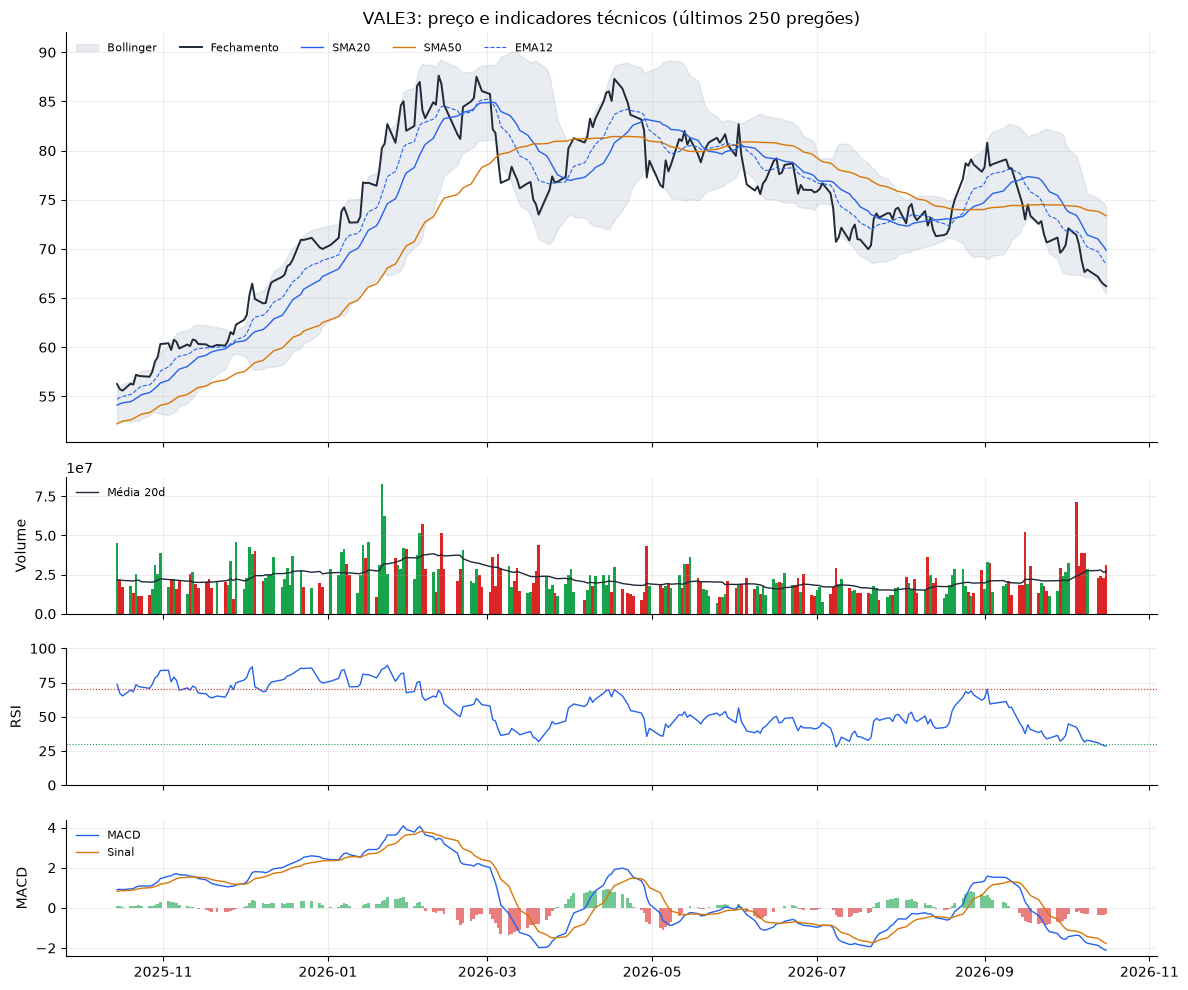

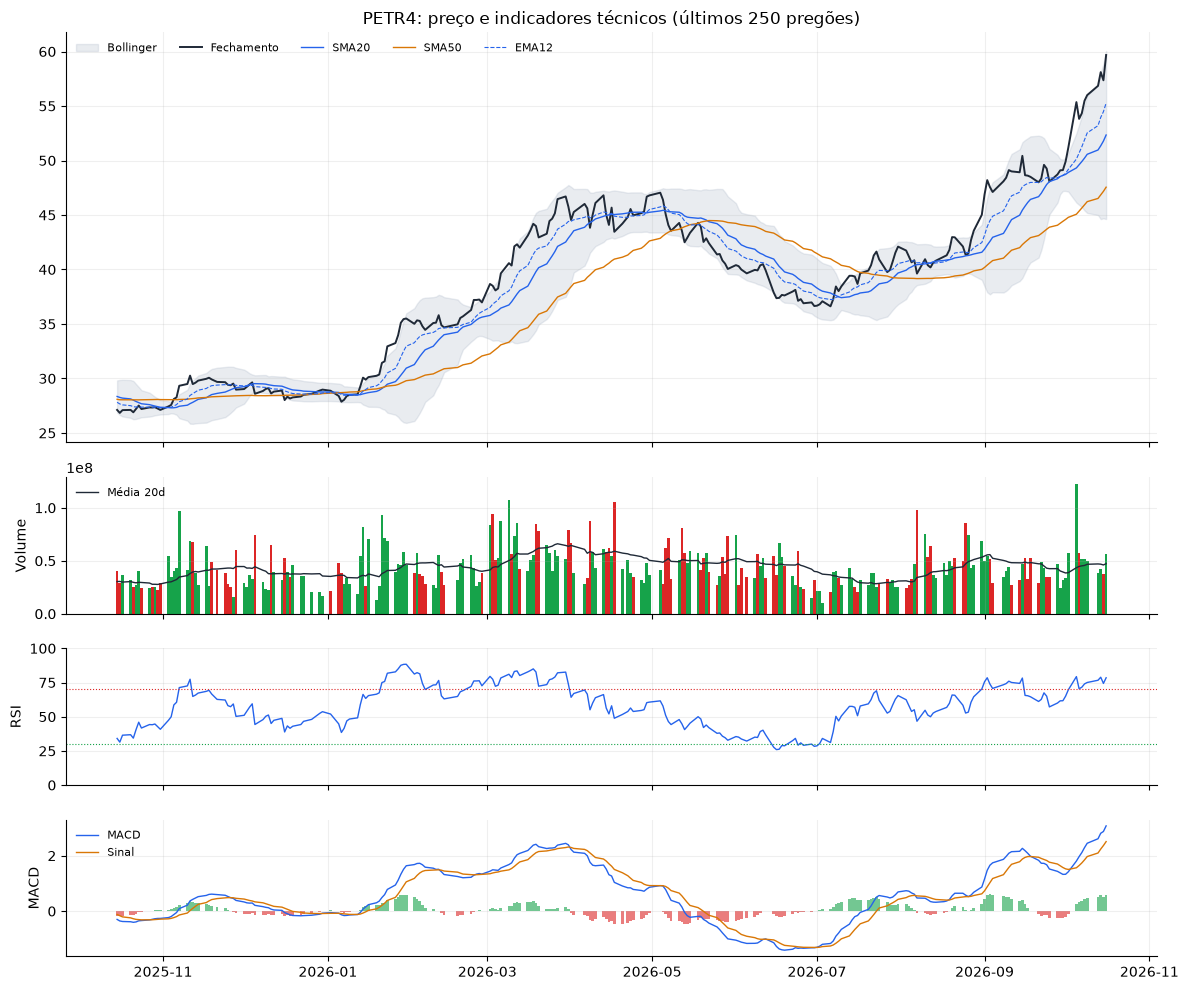

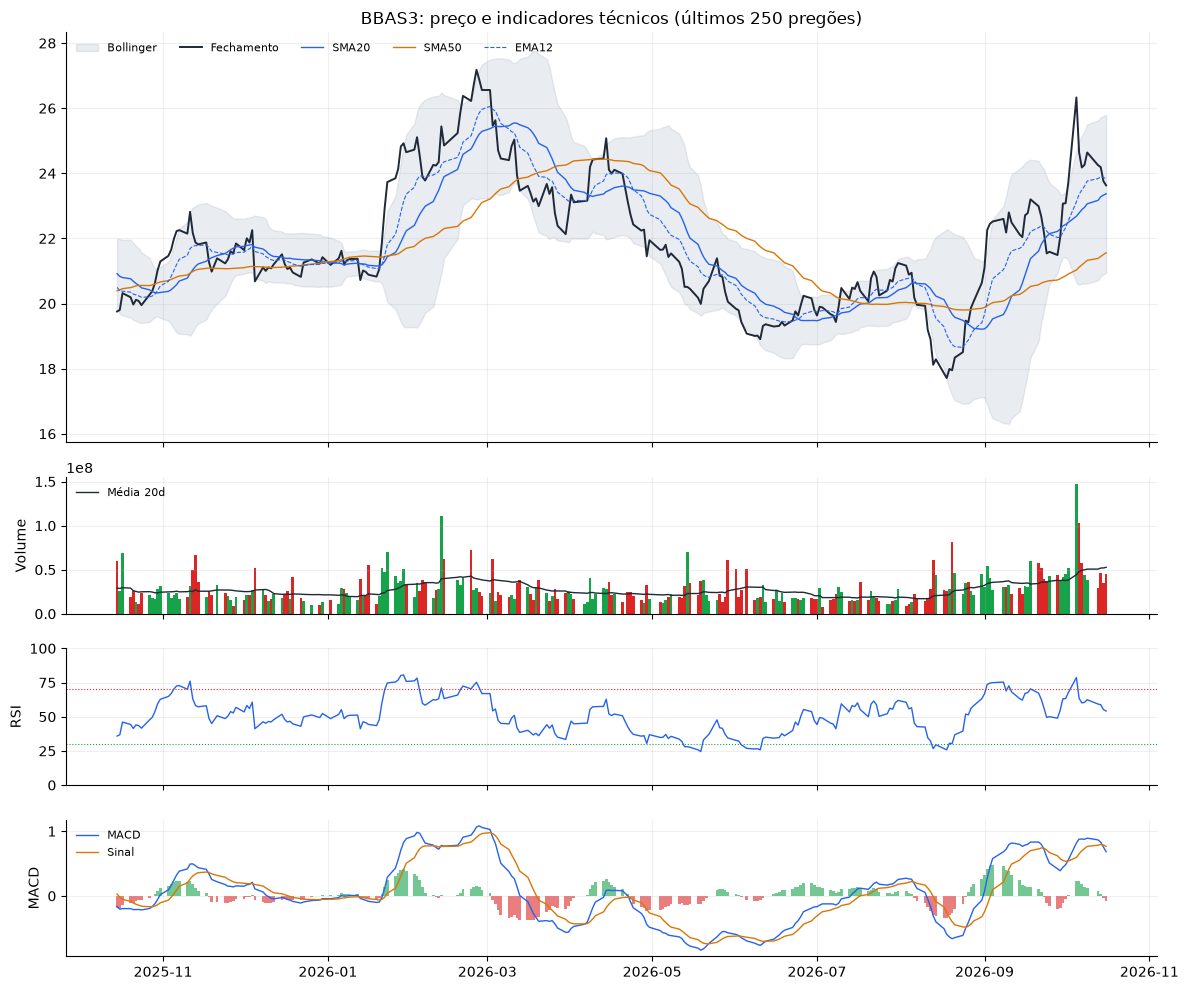

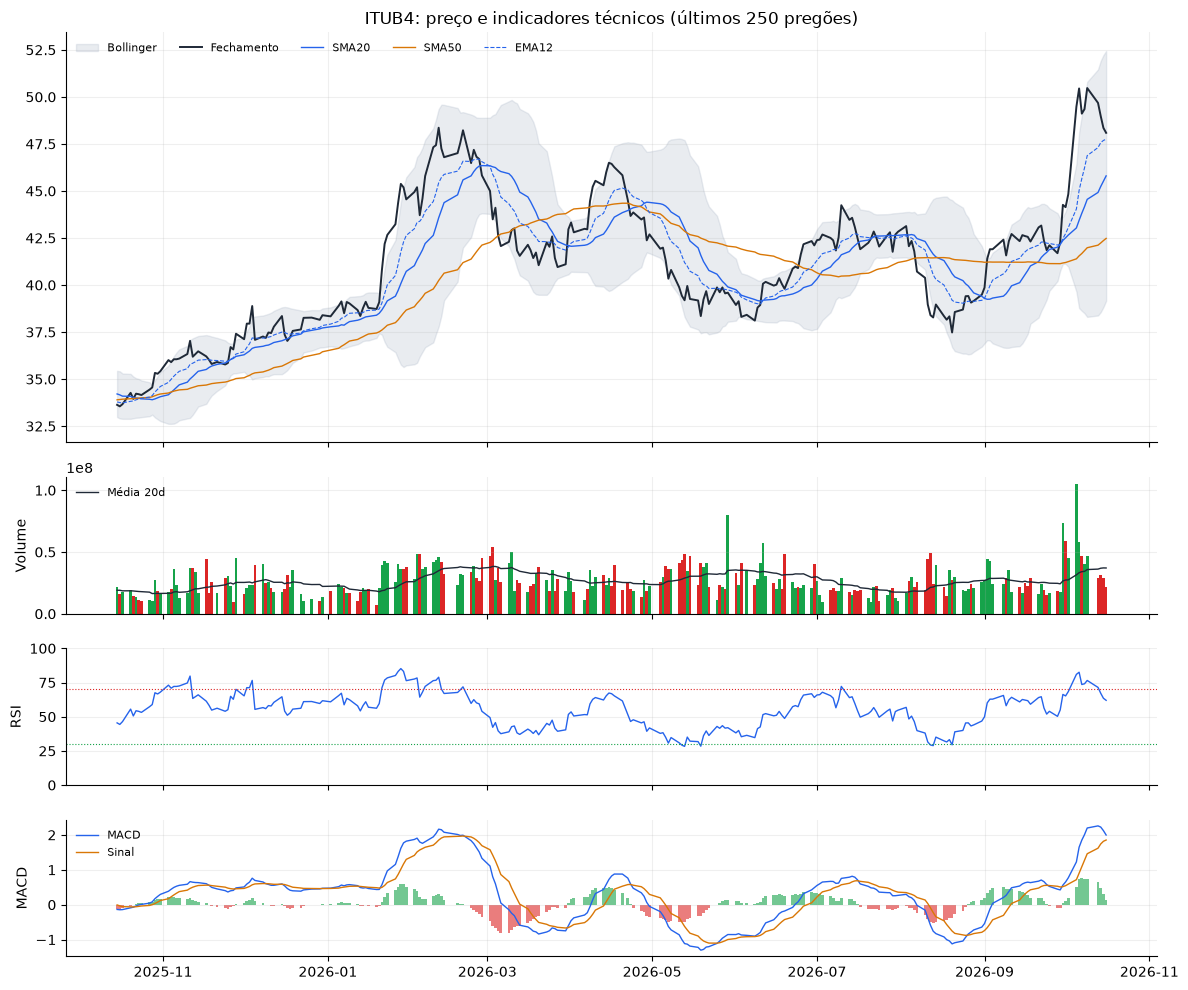

In [9]:
for t in config.STOCKS:
    res = get_price_data(t, config.DEFAULT_PERIOD)
    if res.ok:
        plot_indicators(calculate_indicators(res.data), t)
        plt.show()
    else:
        print(f"{t}: gráfico indisponível ({res.error})")

## 5. Interface conversacional

As respostas usam apenas os registros gerados acima (nenhum dado novo é consultado).

In [10]:
for q in ["Por que você recomendou isso para PETR4 hoje?",
          "Quais notícias foram consideradas para VALE3?",
          "Como estão RSI e MACD de ITUB4?",
          "Quais as limitações da recomendação de BBAS3?",
          "Quais dados foram usados para a Petrobras?"]:
    print("Pergunta:", q)
    print(answer(q, agent.records), "\n")

Pergunta: Por que você recomendou isso para PETR4 hoje?
PETR4 (2026-10-16): recomendação AGUARDAR (score +1.15).
AGUARDAR com score +1.15 (limiares: COMPRAR >= +2.0, VENDER <= -2.0). A favor de alta: SMA20 acima da SMA50 (tendência de alta); MACD acima da linha de sinal; Fechamento acima da SMA50. A favor de baixa: RSI 78.5 > 70 (sobrecomprado).
Sinais que contribuíram:
  - RSI 78.5 > 70 (sobrecomprado) (contribuição -1.00)
  - MACD acima da linha de sinal (contribuição +0.50)
  - Fechamento acima da SMA50 (contribuição +0.50)
  - SMA20 acima da SMA50 (tendência de alta) (contribuição +1.00)
  - Sentimento agregado +0.15 em 15 notícias (neutro) (contribuição +0.15)
(AVISO: recomendações experimentais e educacionais. Não constituem aconselhamento financeiro e não garantem resultados. Desempenho passado não indica desempenho futuro.) 

Pergunta: Quais notícias foram consideradas para VALE3?
VALE3 (2026-10-16): recomendação AGUARDAR (score -1.04).
Notícias consideradas:
15 notícia(s): 0 p

In [11]:
# Faça sua própria pergunta (edite o texto):
print(answer("Por que você recomendou comprar PETR4 hoje?", agent.records))

PETR4 (2026-10-16): recomendação AGUARDAR (score +1.15).
AGUARDAR com score +1.15 (limiares: COMPRAR >= +2.0, VENDER <= -2.0). A favor de alta: SMA20 acima da SMA50 (tendência de alta); MACD acima da linha de sinal; Fechamento acima da SMA50. A favor de baixa: RSI 78.5 > 70 (sobrecomprado).
Sinais que contribuíram:
  - RSI 78.5 > 70 (sobrecomprado) (contribuição -1.00)
  - MACD acima da linha de sinal (contribuição +0.50)
  - Fechamento acima da SMA50 (contribuição +0.50)
  - SMA20 acima da SMA50 (tendência de alta) (contribuição +1.00)
  - Sentimento agregado +0.15 em 15 notícias (neutro) (contribuição +0.15)
(AVISO: recomendações experimentais e educacionais. Não constituem aconselhamento financeiro e não garantem resultados. Desempenho passado não indica desempenho futuro.)


### 5.1. Modo LLM opcional (LangChain + OpenAI ou Gemini)

Isolado do fluxo principal: requer `requirements_llm.txt` e `OPENAI_API_KEY` ou `GOOGLE_API_KEY` no ambiente. Um agente LangChain (tool-calling) recebe **as mesmas ferramentas** e responde em linguagem natural. A recomendação oficial continua vindo das regras auditáveis; o LLM só escolhe ferramentas e redige com base nos resultados delas. Se faltar pacote ou chave, a célula apenas informa e o restante não é afetado. Chamadas a APIs pagas podem gerar custo.

In [ ]:
from assistant.llm_agent import ask_llm, available_providers

print("Provedores com chave:", available_providers() or "nenhum")
print(ask_llm("Por que a recomendação de PETR4 hoje? Cite os indicadores e notícias.", agent.records))

Provedores com chave: nenhum


Modo LLM indisponível: Nenhuma chave OPENAI_API_KEY/GOOGLE_API_KEY disponível neste processo. O fluxo principal (sem chaves) não é afetado.


## 6. Avaliação histórica e backtest

**Definições** (também em `assistant/evaluation.py`):

- Cada decisão em D usa só indicadores calculados com dados **até o fechamento de D** (sem vazamento); os testes automatizados verificam que truncar a série em D não muda nenhuma decisão até D.
- Somente sinais técnicos são avaliados: o RSS não fornece histórico de notícias confiável.
- **Acerto de tendência** (horizonte de 5 pregões, r = Close[D+5]/Close[D] − 1): COMPRAR acerta se r > 0; VENDER, se r < 0; AGUARDAR, se |r| < 2%.
- Decisões sem D+5 disponível não são avaliadas (contadas à parte); os primeiros ~50 pregões (aquecimento dos indicadores) não geram decisão.
- **Taxa base**: % de janelas com r > 0, para comparar com a acurácia de COMPRAR (um "sempre COMPRAR" teria essa acurácia).
- **Backtest long-only:** COMPRAR posiciona, VENDER sai, AGUARDAR mantém a posição; a decisão do fechamento de D rende a partir de D+1; custo de 0,1% por operação; comparado ao Buy-and-Hold no mesmo intervalo.

In [13]:
eval_results, rows = {}, []
for t in config.STOCKS:
    res = get_price_data(t, config.DEFAULT_PERIOD)
    if not res.ok:
        print(f"{t}: avaliação ignorada ({res.error})")
        continue
    out = evaluate_ticker(res.data)
    if "erro" in out:
        print(f"{t}: {out['erro']}")
        continue
    eval_results[t] = out
    m, b = out["metrics"], out["backtest"]
    rows.append({"ticker": t, "período": f"{b['inicio']} a {b['fim']}",
                 "decisões avaliadas": m["decisoes_avaliadas"], "sem D+5": m["sem_horizonte_futuro"],
                 "acurácia geral": m["acuracia_geral"],
                 "acurácia direcional": m["acuracia_direcional_sem_aguardar"],
                 "taxa base de alta": m["taxa_base_alta"],
                 "retorno agente": b["retorno_estrategia"], "retorno buy&hold": b["retorno_buy_and_hold"],
                 "max DD agente": b["max_drawdown_estrategia"], "max DD buy&hold": b["max_drawdown_buy_and_hold"],
                 "operações": b["operacoes"], "exposição": b["exposicao_media"]})
results_df = pd.DataFrame(rows)
if not results_df.empty:
    pct = [c for c in results_df.columns if c not in ("ticker", "período", "decisões avaliadas", "sem D+5", "operações")]
    shown = results_df.copy()
    for c in pct:
        shown[c] = shown[c].map(lambda x: "-" if pd.isna(x) else f"{x:.1%}")
    display(shown)
else:
    print("Sem dados suficientes para avaliação.")

,ticker,período,decisões avaliadas,sem D+5,acurácia geral,acurácia direcional,taxa base de alta,retorno agente,retorno buy&hold,max DD agente,max DD buy&hold,operações,exposição
0,VALE3,2024-12-30 a 2026-10-16,444,5,43.9%,50.0%,58.8%,22.5%,41.1%,-33.4%,-24.4%,8,58.4%
1,PETR4,2024-12-30 a 2026-10-16,444,5,44.1%,38.0%,55.6%,31.4%,95.1%,-28.6%,-22.2%,11,58.4%
2,BBAS3,2024-12-30 a 2026-10-16,444,5,39.4%,44.6%,48.6%,-39.8%,4.7%,-48.0%,-37.6%,11,55.9%
3,ITUB4,2024-12-30 a 2026-10-16,444,5,48.4%,49.1%,59.5%,57.4%,105.5%,-24.3%,-22.5%,7,67.7%


VALE3 {'COMPRAR': 'n=65, acurácia=55.4%', 'VENDER': 'n=65, acurácia=44.6%', 'AGUARDAR': 'n=314, acurácia=41.4%'}


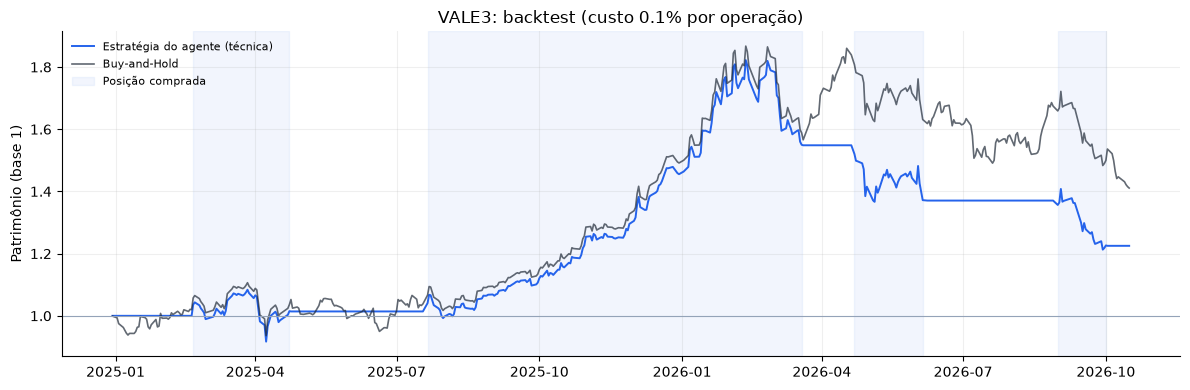

PETR4 {'COMPRAR': 'n=70, acurácia=30.0%', 'VENDER': 'n=51, acurácia=49.0%', 'AGUARDAR': 'n=323, acurácia=46.4%'}


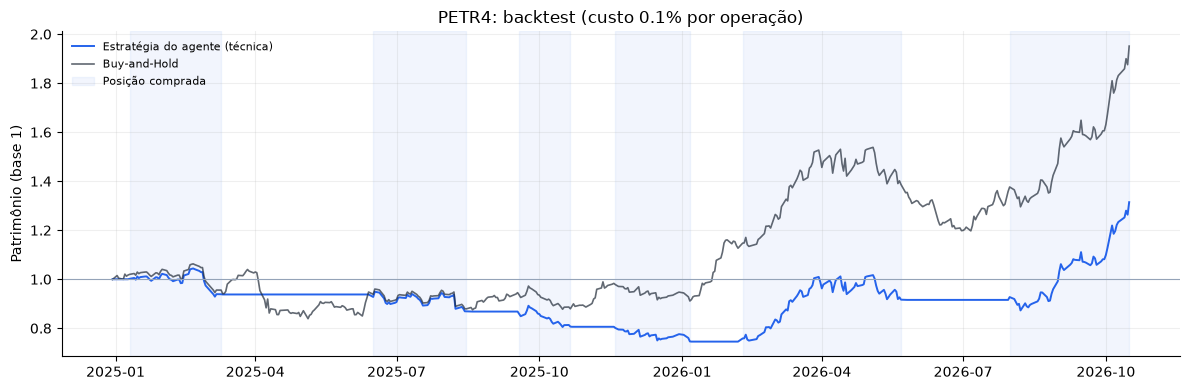

BBAS3 {'COMPRAR': 'n=66, acurácia=43.9%', 'VENDER': 'n=46, acurácia=45.7%', 'AGUARDAR': 'n=332, acurácia=37.7%'}


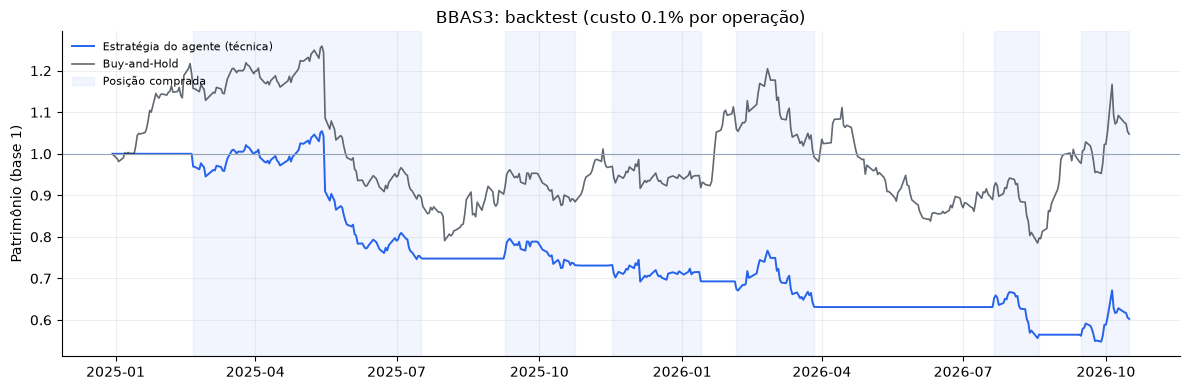

ITUB4 {'COMPRAR': 'n=77, acurácia=55.8%', 'VENDER': 'n=37, acurácia=35.1%', 'AGUARDAR': 'n=330, acurácia=48.2%'}


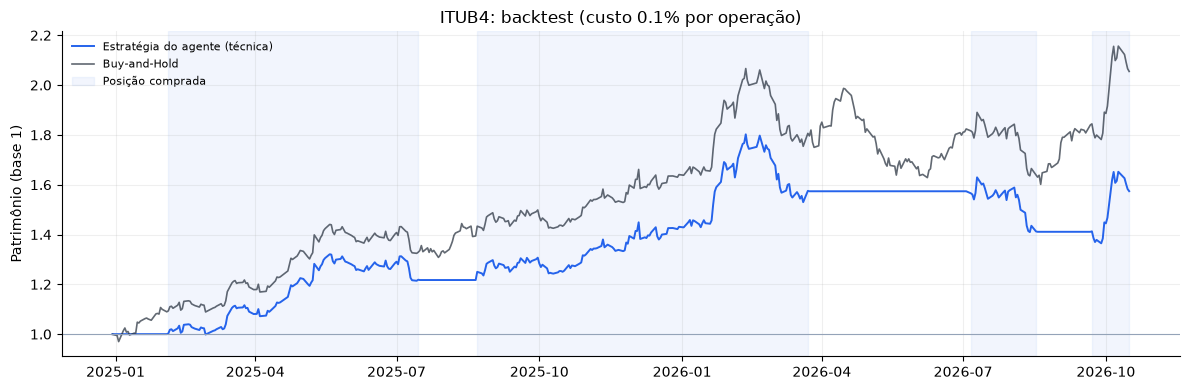

In [14]:
def fmt_class(v):
    acc = "-" if v["acuracia"] is None else f"{v['acuracia']:.1%}"
    return f"n={v['n']}, acurácia={acc}"

for t, out in eval_results.items():
    print(t, {k: fmt_class(v) for k, v in out["metrics"]["por_recomendacao"].items()})
    plot_backtest(out["curve"], t)
    plt.show()

**Leitura dos resultados:** compare a acurácia de COMPRAR com a taxa base de alta e o retorno do agente com o Buy-and-Hold. Regras de tendência (médias/MACD) reagem com atraso e tendem a perder em mercados de alta forte ou lateralizados. Uma única janela de ~2 anos é uma amostra pequena; os números descrevem o passado e **não** indicam desempenho futuro.

**Custos e premissas do backtest:** 0,1% por operação; sem impostos, emolumentos detalhados, slippage ou restrições de liquidez; preços ajustados (dividendos reinvestidos implicitamente); execução no preço de fechamento do dia da decisão; parâmetros não otimizados (evita *overfitting*, mas também não busca o melhor ajuste).

## 7. Premissas e limitações

- Tickers B3 via Yahoo Finance (`.SA`), preços ajustados; dados podem ter atraso ou falhas, tratadas sem interromper o fluxo.
- Feeds RSS públicos (InfoMoney, Money Times, Google News, que agrega Valor, Reuters etc.) podem mudar ou ficar indisponíveis; a Reuters não oferece mais RSS público próprio. Sem notícias, o sentimento não entra na decisão.
- A recomendação considera apenas notícias atuais; a avaliação histórica mede só o componente técnico.
- O sentimento por léxico é simples e pode errar; notícias são relacionadas à ação por ticker/nome no título ou resumo.
- Regras e limiares são heurísticos (`assistant/config.py`), não otimizados.
- O registro do agente contém passos executados, evidências e regras acionadas — não um raciocínio interno simulado.
- Dados fundamentalistas, alertas e multiagente não foram implementados.
- Este material é experimental e não é recomendação de investimento.